<div style="background:linear-gradient(135deg, rgba(249,112,102,0.18), rgba(249,112,102,0.02)); border-left:6px solid #F97066; border-radius:10px; padding:20px 24px; margin-bottom:20px;">
<h1 style="margin:0; color:#F97066; font-size:1.8em;">Implementación de modelos de Machine Learning</h1>
<p style="margin:6px 0 0; opacity:0.8;">Unidad 3 — De la teoría a la práctica: regresión, clasificación, clustering, ensambles y ajuste de hiperparámetros con <code>scikit-learn</code></p>
</div>

La mayoría de los ejemplos de este notebook usan datasets sencillos y muy conocidos (Iris, California Housing) para mostrar el flujo de trabajo completo de cada técnica de la forma más clara posible. Iris, en particular, es un dataset muy simple — solo 4 variables y 3 clases muy bien separadas — por lo que no alcanza para explorar en profundidad temas como la regularización, el sobreajuste, el desbalance de clases o los límites de K-Means. Esos temas se profundizan, con datasets más ricos, en notebooks adicionales junto a este (ver el cierre).

<div style="border:1px solid rgba(14,165,233,0.35); border-radius:10px; padding:14px 20px; margin:16px 0 24px; background:rgba(14,165,233,0.04);">
<strong>📑 Contenido de esta guía</strong>
<ol style="margin:8px 0 0; padding-left:20px;">
<li><a href="#regresion">Aprendizaje supervisado: regresión</a></li>
<li><a href="#clasificacion">Aprendizaje supervisado: clasificación</a></li>
<li><a href="#clustering">Aprendizaje no supervisado: clustering</a></li>
<li><a href="#ensamble">Modelos de ensamble</a></li>
<li><a href="#automl">AutoML con PyCaret</a></li>
<li><a href="#hiperparametros">Optimización de hiperparámetros</a></li>
<li><a href="#cierre">Cierre y próximos pasos</a></li>
</ol>
</div>

<a id="regresion"></a>

## <span style="color:#F97066;">Aprendizaje Supervisado</span>

El **Aprendizaje Supervisado** se caracteriza por entrenar modelos utilizando un conjunto de datos etiquetado. Esto significa que para cada ejemplo de entrenamiento disponemos de la entrada y de la "respuesta correcta" o etiqueta correspondiente, permitiendo al modelo aprender la relación o función matemática que mapea las entradas con las salidas.

### <span style="color:#F97066;">Regresión en Aprendizaje Supervisado</span>

**Regresión Lineal Simple**

Ejemplo: suponiendo los siguientes datos:

<div style="border-radius:12px; overflow:hidden; border:1px solid rgba(14,165,233,0.35); margin:16px 0; max-width:420px;">
<table style="width:100%; border-collapse:collapse; font-size:0.95em;">
<thead>
<tr style="background:#0EA5E9;">
<th style="text-align:left; padding:8px 14px; color:#ffffff;">Tamaño (m²)</th>
<th style="text-align:left; padding:8px 14px; color:#ffffff;">Precio (USD)</th>
</tr>
</thead>
<tbody>
<tr style="background:rgba(14,165,233,0.07);"><td style="padding:6px 14px;">50</td><td style="padding:6px 14px;">100,000</td></tr>
<tr><td style="padding:6px 14px;">80</td><td style="padding:6px 14px;">150,000</td></tr>
<tr style="background:rgba(14,165,233,0.07);"><td style="padding:6px 14px;">120</td><td style="padding:6px 14px;">200,000</td></tr>
</tbody>
</table>
</div>

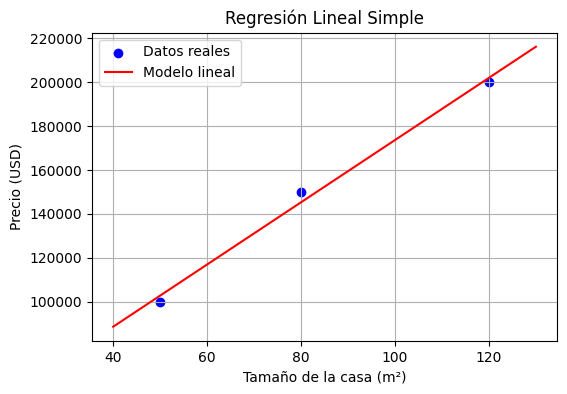

Intercepto (β₀): 31756.75675675676
Pendiente (β₁): 1418.918918918919


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# Datos de ejemplo
X = np.array([[50], [80], [120]])  # Tamaño de la casa (m²)
y = np.array([100000, 150000, 200000])  # Precio

# Crear y ajustar el modelo
modelo = LinearRegression()
modelo.fit(X, y)

# Predicciones
X_pred = np.linspace(40, 130, 100).reshape(-1, 1)
y_pred = modelo.predict(X_pred)

# Visualización
plt.figure(figsize=(6,4))
plt.scatter(X, y, color='blue', label='Datos reales')
plt.plot(X_pred, y_pred, color='red', label='Modelo lineal')
plt.xlabel('Tamaño de la casa (m²)')
plt.ylabel('Precio (USD)')
plt.title('Regresión Lineal Simple')
plt.legend()
plt.grid()
plt.show()

# Coeficientes
print(f"Intercepto (β₀): {modelo.intercept_}")
print(f"Pendiente (β₁): {modelo.coef_[0]}")

### <span style="color:#F97066;">Evaluación de modelos de predicción</span>

In [2]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Datos reales y predicciones
y_real = y
y_pred_real = modelo.predict(X)

# Cálculo de métricas
mae = mean_absolute_error(y_real, y_pred_real)
mse = mean_squared_error(y_real, y_pred_real)
rmse = np.sqrt(mse)
r2 = r2_score(y_real, y_pred_real)

print(f"MAE: {mae:.2f}")
print(f"MSE: {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²: {r2:.4f}")

MAE: 3153.15
MSE: 11261261.26
RMSE: 3355.78
R²: 0.9932


#### **Significado de las métricas de evaluación de regresión**

*   **MAE (Error Absoluto Medio):** Es el promedio de las diferencias absolutas entre los valores reales y las predicciones. Nos da una idea del error promedio en las mismas unidades de la variable objetivo (en este caso, dólares USD), sin importar si la predicción fue por exceso o por defecto. Es menos sensible a valores atípicos (outliers).
*   **MSE (Error Cuadrático Medio):** Es el promedio de los errores al cuadrado. Al elevar los errores al cuadrado, se penalizan mucho más severamente los errores grandes o valores atípicos. Sus unidades están al cuadrado (USD²), lo que dificulta su interpretación directa.
*   **RMSE (Raíz del Error Cuadrático Medio):** Es la raíz cuadrada del MSE. Devuelve el error a las unidades originales de la variable objetivo (USD), manteniendo la penalización a los grandes errores que caracteriza al MSE. Es una de las métricas más utilizadas para optimizar modelos.
*   **R² (Coeficiente de Determinación):** Es una métrica adimensional que indica la proporción de la varianza en los datos reales que es explicada por el modelo. Varía entre 0 y 1 (donde 1 es un ajuste perfecto). Un valor de 0.9932 significa que el modelo explica el 99.32% de la variabilidad de los precios basándose en el tamaño de las casas.

### <span style="color:#F97066;">Ejemplo de regresión: dataset California Housing</span>

El dataset California Housing fue creado a partir del censo de 1990 en California (EE. UU.). Su objetivo es predecir el valor medio de las viviendas en distintos bloques geográficos, a partir de datos socioeconómicos y demográficos.

Variable objetivo (y): <code>MedHouseVal</code> — valor medio de la vivienda (en centenas de miles de dólares)

<div style="border-radius:12px; overflow:hidden; border:1px solid rgba(14,165,233,0.35); margin:16px 0;">
<table style="width:100%; border-collapse:collapse; font-size:0.9em;">
<thead>
<tr style="background:#0EA5E9;">
<th style="text-align:left; padding:8px 14px; color:#ffffff;">Variable</th>
<th style="text-align:left; padding:8px 14px; color:#ffffff;">Descripción</th>
</tr>
</thead>
<tbody>
<tr style="background:rgba(14,165,233,0.07);"><td style="padding:6px 14px;"><code>MedInc</code></td><td style="padding:6px 14px;">Ingreso medio de los hogares en el bloque</td></tr>
<tr><td style="padding:6px 14px;"><code>HouseAge</code></td><td style="padding:6px 14px;">Edad media de las viviendas del bloque</td></tr>
<tr style="background:rgba(14,165,233,0.07);"><td style="padding:6px 14px;"><code>AveRooms</code></td><td style="padding:6px 14px;">Promedio de habitaciones por vivienda</td></tr>
<tr><td style="padding:6px 14px;"><code>AveBedrms</code></td><td style="padding:6px 14px;">Promedio de dormitorios por vivienda</td></tr>
<tr style="background:rgba(14,165,233,0.07);"><td style="padding:6px 14px;"><code>Population</code></td><td style="padding:6px 14px;">Población total del bloque</td></tr>
<tr><td style="padding:6px 14px;"><code>AveOccup</code></td><td style="padding:6px 14px;">Promedio de personas por vivienda</td></tr>
<tr style="background:rgba(14,165,233,0.07);"><td style="padding:6px 14px;"><code>Latitude</code></td><td style="padding:6px 14px;">Latitud geográfica del bloque</td></tr>
<tr><td style="padding:6px 14px;"><code>Longitude</code></td><td style="padding:6px 14px;">Longitud geográfica del bloque</td></tr>
</tbody>
</table>
</div>

<span style="color:#F97066;">1.</span> Importación de librerías

In [3]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

<span style="color:#F97066;">2.</span> Preparación del dataset

In [4]:
data = fetch_california_housing()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target  # Mediana del valor de la vivienda (en cientos de miles)

X

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25
...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32


In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Dimensiones de X_train: {X_train.shape}")
print(f"Dimensiones de y_train: {y_train.shape}")

Dimensiones de X_train: (16512, 8)
Dimensiones de y_train: (16512,)


<span style="color:#F97066;">3.</span> Creación y entrenamiento del modelo de Regresión Lineal

In [6]:
modelo = LinearRegression()
modelo.fit(X_train, y_train)

LinearRegression()

<span style="color:#F97066;">4.</span> Predicción del conjunto de prueba

In [7]:
y_pred = modelo.predict(X_test)
y_pred

array([0.71912284, 1.76401657, 2.70965883, ..., 4.46877017, 1.18751119,
       2.00940251])

<span style="color:#F97066;">5.</span> Evaluación del modelo

In [8]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Evaluación del Modelo:")
print(f"MAE: {mae:.3f}")
print(f"MSE: {mse:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R²: {r2:.4f}")

Evaluación del Modelo:
MAE: 0.533
MSE: 0.556
RMSE: 0.746
R²: 0.5758


<span style="color:#F97066;">6.</span> Visualización de valores predichos vs. valores reales

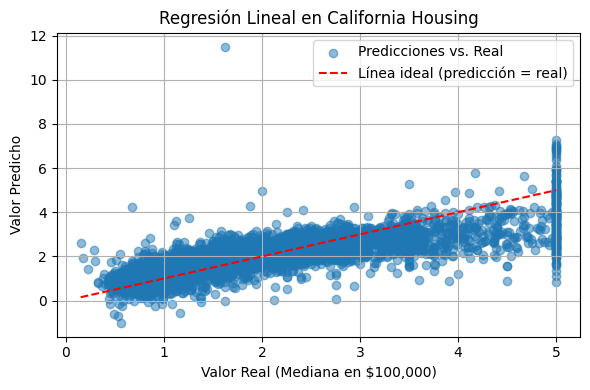

In [9]:
plt.figure(figsize=(6, 4))
plt.scatter(y_test, y_pred, alpha=0.5, label="Predicciones vs. Real")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', label="Línea ideal (predicción = real)")
plt.xlabel("Valor Real (Mediana en $100,000)")
plt.ylabel("Valor Predicho")
plt.title("Regresión Lineal en California Housing")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

### Conclusión de la visualización (California Housing)

Al analizar el gráfico de **Valores Predichos vs. Valores Reales**, podemos extraer las siguientes conclusiones sobre el desempeño de nuestro modelo de regresión lineal:

1. **Tendencia General:** Los puntos se distribuyen siguiendo de cerca la línea diagonal discontinua (línea ideal), lo que demuestra que el modelo captura correctamente la tendencia ascendente del valor de las viviendas a medida que aumentan sus características socioeconómicas (como el ingreso medio `MedInc`).
2. **Dispersión y Error:** Existe una dispersión notable a lo largo de la diagonal, reflejada en el **MAE de 0.533** y el **RMSE de 0.746**. Esto significa que las predicciones suelen tener un desvío promedio de aproximadamente \$ 53,300 USD respecto al valor real.
3. **El Efecto del Límite (Truncamiento a 5.0):** Se observa una línea vertical de puntos acumulados exactamente en el valor real de `5.0` (que representa $500,000 USD). Esto ocurre porque en el dataset original los valores de las casas por encima de ese monto fueron truncados a ese tope. Al ser un comportamiento artificial no lineal de los datos, el modelo lineal tiene dificultades para predecirlo con exactitud, subestimando la mayoría de estos casos.

### <span style="color:#F97066;">Clasificación en Aprendizaje Supervisado</span>

#### <span style="color:#F97066;">k-Nearest Neighbors (k-NN)</span>

k-NN es un algoritmo de clasificación basado en la proximidad. Para clasificar un nuevo ejemplo, el modelo:

1. Busca los k vecinos más cercanos en el conjunto de entrenamiento.
2. Toma una votación (clasificación) o promedio (regresión) según las clases de esos vecinos.
3. Es especialmente útil en problemas donde la geometría del espacio de características es relevante.

Para clasificar un punto nuevo $(x,y)$, el algoritmo busca sus k vecinos más cercanos según una métrica (por defecto, distancia Euclidiana):

$$\text{dist}(x, x_i) = \sqrt{\sum (x_j - x_{i,j})^2}$$

A continuación, una implementación de k-NN sobre el **dataset Iris**, aprovechando su característica multiclase.

In [10]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix

# 1. Cargar datos
iris = load_iris()
X, y = iris.data, iris.target

# 2. Escalar datos (importante para k-NN)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. División en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# 4. Entrenar modelo k-NN
modelo_knn = KNeighborsClassifier(n_neighbors=5, metric='euclidean', weights='uniform')
modelo_knn.fit(X_train, y_train)

# 5. Predicciones y evaluación
y_pred = modelo_knn.predict(X_test)
print("Matriz de Confusión:\n", confusion_matrix(y_test, y_pred))
print("\nReporte de Clasificación:\n", classification_report(y_test, y_pred))

Matriz de Confusión:
 [[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]

Reporte de Clasificación:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



La matriz de confusión cruza la clase real (filas) con la clase predicha por el modelo (columnas): en la diagonal quedan los aciertos, y fuera de ella, los errores. Aquí sale perfectamente diagonal — sin ningún error — precisamente porque Iris es un dataset muy simple con clases muy bien separadas.

El reporte de clasificación añade, por cada clase, tres métricas: **precision** (de las veces que el modelo predijo esa clase, cuántas acertó), **recall** (de todos los ejemplos que realmente eran de esa clase, a cuántos identificó) y **f1-score** (su combinación). Con Iris las tres valen 1.00 en todas las clases, así que no hay margen para ver diferencias entre ellas.

<div style="border-left:4px solid #6366F1; background:rgba(99,102,241,0.08); border-radius:6px; padding:10px 16px; margin:16px 0;">
<strong>📝 Nota</strong><br>
En este curso, "precisión" también se ha usado como sinónimo de <em>accuracy</em> (el porcentaje total de aciertos). A partir de aquí conviene distinguirlos: <em>accuracy</em> es una única cifra sobre el total de predicciones, mientras que <em>precision</em> (una columna del reporte anterior) se calcula por clase y responde una pregunta más específica. Con clases desbalanceadas, dos modelos con la misma accuracy pueden tener precision y recall muy distintos por clase — la matriz de confusión y estas métricas se explican formalmente, con un ejemplo donde sí generan diferencias visibles, en <code>6-pipelines-evaluacion.ipynb</code>.
</div>

#### **Visualización de las Fronteras de Decisión de k-NN en el Dataset Iris (2D)**

Dado que el dataset Iris tiene 4 características, para poder visualizar las regiones de decisión en un plano bidimensional, seleccionaremos únicamente dos de ellas: **Petal Length** (longitud del pétalo) y **Petal Width** (ancho del pétalo).

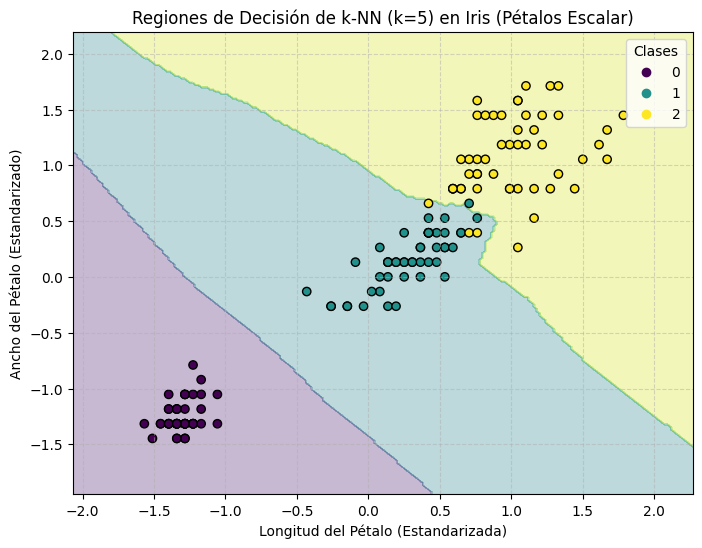

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

# 1. Cargar datos e instanciar solo las variables de los pétalos (columnas 2 y 3)
iris = load_iris()
X_2d = iris.data[:, [2, 3]]
y_2d = iris.target

# 2. Escalar características
scaler_2d = StandardScaler()
X_2d_scaled = scaler_2d.fit_transform(X_2d)

# 3. Entrenar el clasificador k-NN (k=5)
modelo_knn_2d = KNeighborsClassifier(n_neighbors=5, metric='euclidean')
modelo_knn_2d.fit(X_2d_scaled, y_2d)

# 4. Crear la malla de puntos para graficar las fronteras
h = 0.02
x_min, x_max = X_2d_scaled[:, 0].min() - 0.5, X_2d_scaled[:, 0].max() + 0.5
y_min, y_max = X_2d_scaled[:, 1].min() - 0.5, X_2d_scaled[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

# Predecir sobre cada punto de la malla
Z = modelo_knn_2d.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# 5. Graficar
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='viridis')

# Dibujar los puntos del dataset
scatter = plt.scatter(X_2d_scaled[:, 0], X_2d_scaled[:, 1], c=y_2d, edgecolor='k', cmap='viridis')

plt.title("Regiones de Decisión de k-NN (k=5) en Iris (Pétalos Escalar)")
plt.xlabel("Longitud del Pétalo (Estandarizada)")
plt.ylabel("Ancho del Pétalo (Estandarizado)")
plt.legend(*scatter.legend_elements(), title="Clases")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Ejemplo de clasificación y visualización de las regiones de decisión de k-NN en 2D

Matriz de Confusión:
 [[12  2  6]
 [ 3 15  1]
 [ 0  0 21]]

Reporte de Clasificación:
               precision    recall  f1-score   support

           0       0.80      0.60      0.69        20
           1       0.88      0.79      0.83        19
           2       0.75      1.00      0.86        21

    accuracy                           0.80        60
   macro avg       0.81      0.80      0.79        60
weighted avg       0.81      0.80      0.79        60



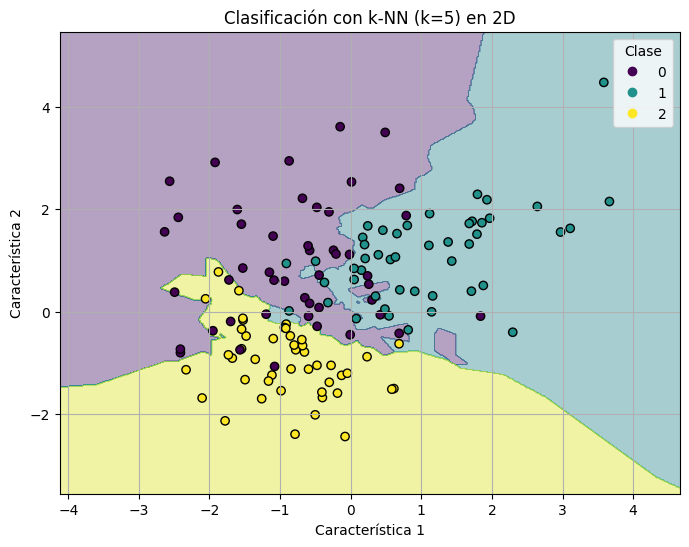

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

# 1. Crear un conjunto de datos 2D
X, y = make_classification(
    n_samples=200,  # Número de muestras
    n_features=2,  # Solo dos características
    n_redundant=0,
    n_clusters_per_class=1,
    n_classes=3,
    random_state=42,
)

# 2. Dividir en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# 3. Entrenar el modelo k-NN
modelo = KNeighborsClassifier(n_neighbors=5)
modelo.fit(X_train, y_train)

# 4. Visualización de regiones de decisión
y_pred = modelo.predict(X_test)
print("Matriz de Confusión:\n", confusion_matrix(y_test, y_pred))
print("\nReporte de Clasificación:\n", classification_report(y_test, y_pred))

# Crear una malla de puntos (rejilla) para cubrir el espacio de características
h = 0.02
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

# Predecir la clase para cada punto de la malla
Z = modelo.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Dibujar la región de decisión
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.4, cmap="viridis")

# Dibujar los puntos de entrenamiento
scatter = plt.scatter(
    X_train[:, 0], X_train[:, 1], c=y_train, edgecolor="k", cmap="viridis"
)
plt.title("Clasificación con k-NN (k=5) en 2D")
plt.xlabel("Característica 1")
plt.ylabel("Característica 2")
plt.legend(*scatter.legend_elements(), title="Clase")
plt.grid(True)
plt.show()

#### <span style="color:#F97066;">Árboles de Decisión (Decision Trees)</span>

Ejemplo de clasificación con Árboles de Decisión sobre el conjunto de datos Iris.

Matriz de confusión:
 [[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]

Reporte de clasificación:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        19
           1       1.00      1.00      1.00        13
           2       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



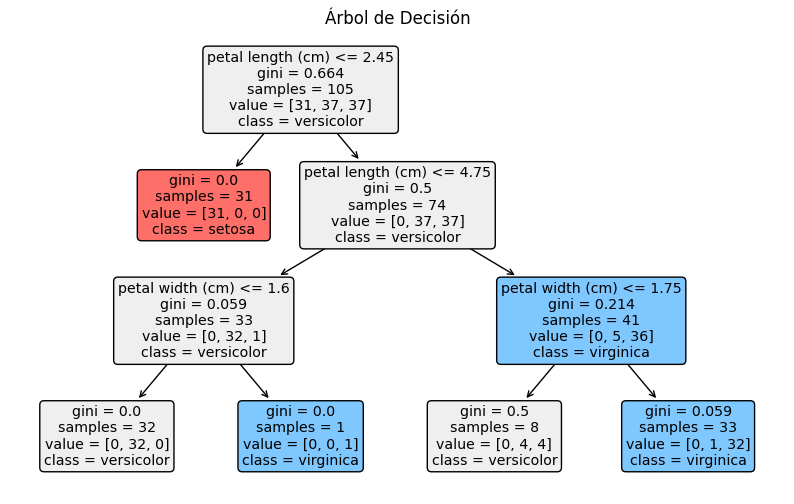

In [13]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

# 1. Cargar datos
iris = load_iris()
X, y = iris.data, iris.target

# 2. Dividir datos en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# 3. Crear y entrenar modelo de Árbol de Decisión
modelo = DecisionTreeClassifier(criterion="gini", max_depth=3, random_state=42)
modelo.fit(X_train, y_train)

# 4. Evaluar modelo
y_pred = modelo.predict(X_test)
print("Matriz de confusión:\n", confusion_matrix(y_test, y_pred))
print("\nReporte de clasificación:\n", classification_report(y_test, y_pred))

# 5. Visualizar el árbol con colores personalizados más claros
plt.figure(figsize=(10, 6))

# Colores
colores_clase = {0: "#FF6F69", 1: "#F0EFEF", 2: "#7FC7FF"}

# Dibujar el árbol básico
arbol_dibujado = plot_tree(
    modelo,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True,
)

# Aplicar los colores personalizados a cada nodo según su clase dominante
for nodo in arbol_dibujado:
    texto = nodo.get_text()
    # Identificar la clase dominante leyendo el texto del nodo
    if "class = setosa" in texto:
        nodo.get_bbox_patch().set_facecolor(colores_clase[0])
        nodo.get_bbox_patch().set_edgecolor("black")
    elif "class = versicolor" in texto:
        nodo.get_bbox_patch().set_facecolor(colores_clase[1])
        nodo.get_bbox_patch().set_edgecolor("black")
    elif "class = virginica" in texto:
        nodo.get_bbox_patch().set_facecolor(colores_clase[2])
        nodo.get_bbox_patch().set_edgecolor("black")

plt.title("Árbol de Decisión")
plt.show()

Al analizar la estructura del árbol de decisión entrenado, podemos destacar los siguientes aspectos fundamentales sobre su funcionamiento:

1. **Reglas de Decisión Intuitivas:** La principal ventaja de este modelo es su gran interpretabilidad. Podemos seguir el camino desde la raíz hasta las hojas para entender exactamente por qué se clasifica una muestra en una categoría específica.
2. **Importancia de Características (Features):** El nodo raíz realiza la primera división utilizando la variable `petal length (cm) <= 2.45`. Si esta condición es verdadera, clasifica inmediatamente la muestra como **Setosa** con una pureza absoluta (índice Gini = 0.0), lo que demuestra que esta característica es sumamente discriminativa para separar esta clase de las demás.
3. **Criterio de Impureza de Gini:** El índice Gini mide el grado de impureza de los nodos (siendo 0.0 un nodo completamente puro donde todas las muestras pertenecen a una única clase). A medida que descendemos por las ramas, el algoritmo busca reducir este índice hasta alcanzar hojas homogéneas.
4. **Control de Complejidad (max_depth):** Al limitar la profundidad máxima del árbol a `3` (`max_depth=3`), evitamos que el árbol crezca indefinidamente, lo cual previene el sobreajuste (overfitting) y mantiene el modelo simple y generalizable.

<a id="clustering"></a>

## <span style="color:#F97066;">Aprendizaje No Supervisado</span>

El **Aprendizaje No Supervisado** trabaja con datos que no tienen etiquetas o respuestas predefinidas. El objetivo del modelo es explorar la estructura interna de los datos para encontrar patrones latentes, relaciones, similitudes o agrupaciones naturales entre las observaciones por sí mismo.

### <span style="color:#F97066;">Clustering</span>

El clustering es una técnica que busca agrupar instancias similares en conjuntos llamados clústeres, sin usar etiquetas previas.

<div style="border-left:4px solid #6366F1; background:rgba(99,102,241,0.08); border-radius:6px; padding:10px 16px; margin:16px 0;">
<strong>🎯 Objetivo</strong><br>
Descubrir estructura o patrones ocultos en los datos, asignando a cada observación un grupo basado en su proximidad o similitud — sin conocer de antemano la "respuesta correcta".
</div>

#### <span style="color:#F97066;">Clustering con K-Means</span>

K-Means es un algoritmo de agrupamiento que busca dividir los datos en k grupos o clústeres, de modo que los puntos dentro de cada clúster sean lo más similares posible entre sí, y lo más diferentes posible de los de otros clústeres.

<div style="border-left:4px solid #6366F1; background:rgba(99,102,241,0.08); border-radius:6px; padding:10px 16px; margin:16px 0;">
<strong>📝 Nota</strong><br>
K-Means asume que los clústeres son aproximadamente esféricos y de tamaño similar, y requiere fijar <code>k</code> de antemano. Qué ocurre cuando esa suposición falla (clústeres alargados, anidados o de formas irregulares) y cómo elegir <code>k</code> de forma objetiva se exploran con más detalle en <code>4-aprendizaje-no-supervisado.ipynb</code>.
</div>

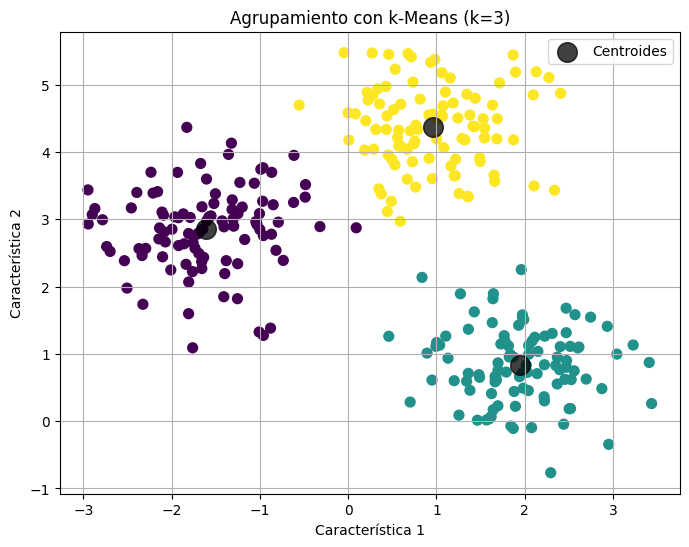

Puntaje Silhouette: 0.660


In [14]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Generar un conjunto de datos 2D simulado con 3 centros
X, y_true = make_blobs(n_samples=300, centers=3, cluster_std=0.6, random_state=0)

# 2. Crear y ajustar el modelo k-Means
k = 3
modelo = KMeans(n_clusters=k, n_init="auto", random_state=0)
y_kmeans = modelo.fit_predict(X)

# 3. Visualizar los clusters encontrados
plt.figure(figsize=(8,6))
plt.scatter(X[:, 0], X[:, 1], c=y_kmeans, s=50, cmap='viridis')
plt.scatter(modelo.cluster_centers_[:, 0], modelo.cluster_centers_[:, 1], c='black', s=200, alpha=0.75, label='Centroides')
plt.title("Agrupamiento con k-Means (k=3)")
plt.xlabel("Característica 1")
plt.ylabel("Característica 2")
plt.legend()
plt.grid(True)
plt.show()

# 4. Evaluar la calidad del clustering con Silhouette Score
sil_score = silhouette_score(X, y_kmeans)
print(f"Puntaje Silhouette: {sil_score:.3f}")

#### **Métrica de Evaluación: Coeficiente de Silhouette (Silhouette Score)**

El **coeficiente de Silhouette** es una métrica utilizada para medir la calidad de un agrupamiento (clustering) sin necesidad de contar con etiquetas de referencia. Mide qué tan similar es un objeto a su propio clúster (cohesión) en comparación con otros clústeres contiguos (separación).

Para un punto individual $i$, su coeficiente de silhouette $s(i)$ se define como:

$$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$$

Donde:
*   **$a(i)$**: Es la distancia promedio entre el punto $i$ y todos los demás puntos del mismo clúster (cohesión interna).
*   **$b(i)$**: Es la distancia promedio más pequeña desde el punto $i$ hacia todos los puntos de cualquier otro clúster, del cual $i$ no es miembro (separación con el vecino más cercano).

##### **Interpretación del rango de valores:**

El coeficiente global de Silhouette es el promedio del valor $s(i)$ de todos los puntos y varía estrictamente en el rango de **$[-1, 1]$**:

*   **Valores cercanos a $+1$**: Indican que los puntos están muy bien agrupados en sus propios clústeres y muy alejados de los clústeres vecinos (agrupamiento excelente).
*   **Valores cercanos a $0$**: Sugieren que los puntos están localizados muy cerca de las fronteras de decisión entre dos clústeres vecinos (clústeres superpuestos o difusos).
*   **Valores cercanos a $-1$**: Indican que las muestras se han asignado al clúster equivocado, ya que están más cerca de un clúster vecino que del propio.

<a id="ensamble"></a>

## <span style="color:#F97066;">Modelos Avanzados de Machine Learning</span>

### <span style="color:#F97066;">Modelos de Ensamble</span>

Un modelo de ensamble combina múltiples modelos base (por lo general, débiles o moderados) para formar un modelo más robusto y preciso.

#### <span style="color:#F97066;">Random Forest</span>

Ejemplo completo de clasificación con **Random Forest** usando el dataset de Iris. Incluye entrenamiento, evaluación y análisis de la importancia de características.

In [15]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import pandas as pd

# 1. Cargar datos
iris = load_iris()
X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = iris.target

# 2. Dividir en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 3. Crear y entrenar modelo Random Forest
modelo = RandomForestClassifier(n_estimators=100, random_state=42)
modelo.fit(X_train, y_train)

# 4. Predicción y evaluación
y_pred = modelo.predict(X_test)

print("Matriz de Confusión:\n", confusion_matrix(y_test, y_pred))
print("\nReporte de Clasificación:\n", classification_report(y_test, y_pred, target_names=iris.target_names))


Matriz de Confusión:
 [[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]

Reporte de Clasificación:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



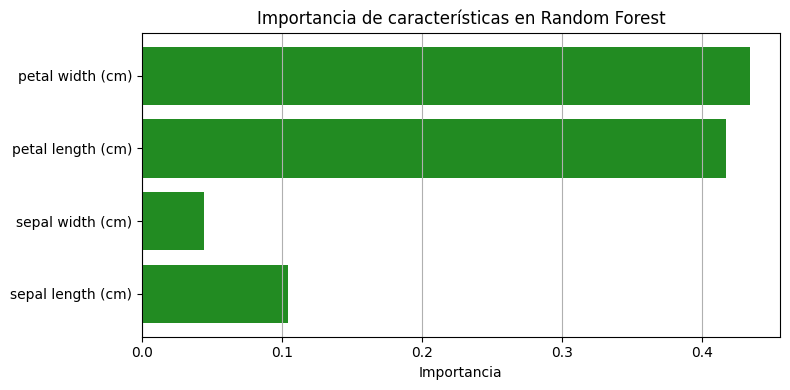

In [16]:
# 5. Importancia de características
importancias = modelo.feature_importances_
features = X.columns

# Visualizar
plt.figure(figsize=(8, 4))
plt.barh(features, importancias, color='forestgreen')
plt.xlabel("Importancia")
plt.title("Importancia de características en Random Forest")
plt.grid(axis='x')
plt.tight_layout()
plt.show()

#### <span style="color:#F97066;">XGBoost</span>

Ejemplo de XGBoost usando el dataset Iris, incluyendo entrenamiento, evaluación y análisis de la importancia de las características.

<div style="border-left:4px solid #6366F1; background:rgba(99,102,241,0.08); border-radius:6px; padding:10px 16px; margin:16px 0;">
<strong>📝 Nota</strong><br>
Random Forest (bagging) y XGBoost (boosting) combinan árboles de formas muy distintas. La comparación directa entre bagging, boosting (AdaBoost, Gradient Boosting, LightGBM) y técnicas de combinación como voting y stacking se profundiza en <code>5-modelos-ensamble.ipynb</code>.
</div>

In [17]:
%pip install xgboost

/Users/sebastiancely/Documents/GitHub/IA-Course-UdB/Unidad 3/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


In [18]:
import xgboost as xgb
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import pandas as pd

# 1. Cargar datos
iris = load_iris()
X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = iris.target

# 2. Dividir en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# 3. Crear y entrenar modelo XGBoost
modelo = xgb.XGBClassifier(
    objective="multi:softmax",
    num_class=3,
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    eval_metric="mlogloss",
)

modelo.fit(X_train, y_train)

# 4. Evaluar el modelo
y_pred = modelo.predict(X_test)
print("Matriz de Confusión:\n", confusion_matrix(y_test, y_pred))
print(
    "\nReporte de Clasificación:\n",
    classification_report(y_test, y_pred, target_names=iris.target_names),
)

Matriz de Confusión:
 [[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]

Reporte de Clasificación:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



Visualización de la importancia de características

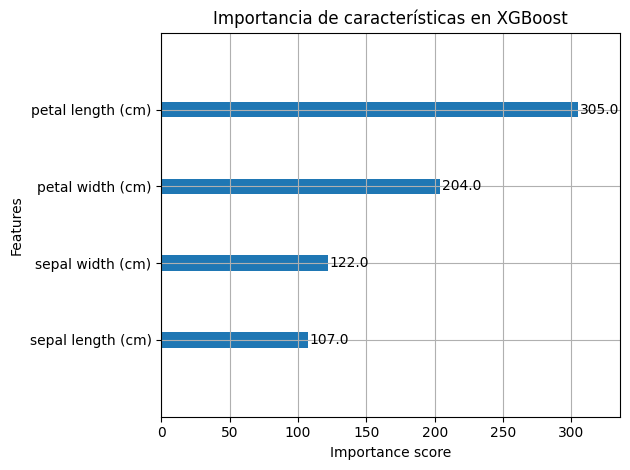

In [19]:
# 5. Importancia de variables
xgb.plot_importance(modelo)
plt.title("Importancia de características en XGBoost")
plt.tight_layout()
plt.show()

<a id="automl"></a>

### <span style="color:#F97066;">AutoML</span>

#### <span style="color:#F97066;">PyCaret</span>

<span style="color:#F97066;">1.</span> Instalación en el entorno. Preferiblemente un entorno virtual limpio.

<div style="border-left:4px solid #6366F1; background:rgba(99,102,241,0.08); border-radius:6px; padding:10px 16px; margin:16px 0;">
<strong>📝 Nota</strong><br>
PyCaret fija rangos de versiones bastante estrictos para <code>numpy</code>, <code>scikit-learn</code>, <code>scipy</code> y otras librerías. Instalarlo en el mismo entorno donde ya tiene versiones recientes de estas librerías (como las usadas en las secciones anteriores de este notebook) puede generar conflictos de dependencias o downgrades inesperados. Se recomienda crear un entorno virtual dedicado solo para la sección de PyCaret.
</div>

In [ ]:
%pip install pycaret

In [21]:
from pycaret.datasets import get_data
from pycaret.classification import *

# 1. Cargar el dataset Iris
iris = get_data('iris')

# 2. Configurar el entorno de PyCaret (setup)
# Se define 'species' como la variable objetivo
exp = setup(data=iris, target='species', session_id=42, verbose=False)

# 3. Comparar automáticamente múltiples modelos
best_model = compare_models()

# 4. Evaluar el mejor modelo
evaluate_model(best_model)

# 5. Predecir sobre nuevos datos
predictions = predict_model(best_model)
print(predictions.head())

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
qda,Quadratic Discriminant Analysis,0.9809,0.0000,0.9809,0.9852,0.9805,0.9711,0.9735,0.0060
nb,Naive Bayes,0.9727,0.9974,0.9727,0.9806,0.9714,0.9588,0.9638,0.0040
lda,Linear Discriminant Analysis,0.9718,0.0000,0.9718,0.9780,0.9712,0.9573,0.9609,0.0040
et,Extra Trees Classifier,0.9718,1.0000,0.9718,0.9780,0.9712,0.9573,0.9609,0.0150
lr,Logistic Regression,0.9618,0.0000,0.9618,0.9705,0.9610,0.9422,0.9470,0.6950
ada,Ada Boost Classifier,0.9618,0.0000,0.9618,0.9705,0.9610,0.9422,0.9470,0.0160
knn,K Neighbors Classifier,0.9527,0.9888,0.9527,0.9595,0.9520,0.9284,0.9322,0.0080
rf,Random Forest Classifier,0.9518,0.9951,0.9518,0.9660,0.9487,0.9270,0.9352,0.0210
gbc,Gradient Boosting Classifier,0.9518,0.0000,0.9518,0.9660,0.9487,0.9270,0.9352,0.0160
xgboost,Extreme Gradient Boosting,0.9436,0.9847,0.9436,0.9588,0.9417,0.9149,0.9236,0.0170


interactive(children=(ToggleButtons(description='Plot Type:', icons=('',), options=(('Pipeline Plot', 'pipelin…

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Quadratic Discriminant Analysis,0.9778,1.0000,0.9778,0.9792,0.9778,0.9667,0.9674


     sepal_length  sepal_width  petal_length  petal_width          species  \
107           7.3          2.9           6.3          1.8   Iris-virginica   
63            6.1          2.9           4.7          1.4  Iris-versicolor   
133           6.3          2.8           5.1          1.5   Iris-virginica   
56            6.3          3.3           4.7          1.6  Iris-versicolor   
127           6.1          3.0           4.9          1.8   Iris-virginica   

    prediction_label  prediction_score  
107   Iris-virginica            0.9998  
63   Iris-versicolor            0.9923  
133  Iris-versicolor            0.7679  
56   Iris-versicolor            0.9913  
127   Iris-virginica            0.8300  


**Es posible exportar el modelo:**

In [22]:
save_model(best_model, 'mejor_modelo_pycaret')

Transformation Pipeline and Model Successfully Saved


(Pipeline(memory=Memory(location=None),
          steps=[('label_encoding',
                  TransformerWrapperWithInverse(exclude=None, include=None,
                                                transformer=LabelEncoder())),
                 ('numerical_imputer',
                  TransformerWrapper(exclude=None,
                                     include=['sepal_length', 'sepal_width',
                                              'petal_length', 'petal_width'],
                                     transformer=SimpleImputer(add_indicator=False,
                                                               copy=True,
                                                               fill_value=None,
                                                               keep_empt...
                                                               strategy='mean'))),
                 ('categorical_imputer',
                  TransformerWrapper(exclude=None, include=[],
                        

**Se puede cargar nuevamente en una variable:**

In [23]:
modelo = load_model('mejor_modelo_pycaret')

Transformation Pipeline and Model Successfully Loaded


<a id="hiperparametros"></a>

## <span style="color:#F97066;">Optimización de Hiperparámetros</span>

### <span style="color:#F97066;">Grid Search</span>

Optimización de hiperparámetros para el dataset de Iris con k-NN, probando exhaustivamente todas las combinaciones del espacio de búsqueda definido.

In [24]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report

# 1. Cargar datos
iris = load_iris()
X, y = iris.data, iris.target

# 2. Dividir en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 3. Definir el modelo base
knn = KNeighborsClassifier()

# 4. Definir el espacio de hiperparámetros
param_grid = {
    'n_neighbors': [3, 5, 7, 9],
    'weights': ['uniform', 'distance'],
    'p': [1, 2]  # 1 = Manhattan, 2 = Euclidiana
}

# 5. Instanciar GridSearchCV
grid_search = GridSearchCV(knn, param_grid, cv=5, scoring='accuracy', n_jobs=-1, verbose=1)

# 6. Ejecutar búsqueda
grid_search.fit(X_train, y_train)

# 7. Resultados
print(f"Mejores hiperparámetros encontrados:\n{grid_search.best_params_}")
print(f"Mejor puntuación en CV: {grid_search.best_score_:.3f}")

# 8. Evaluar sobre datos de prueba
y_pred = grid_search.predict(X_test)
print("\nEvaluación sobre conjunto de prueba:")
print(classification_report(y_test, y_pred))

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Mejores hiperparámetros encontrados:
{'n_neighbors': 7, 'p': 2, 'weights': 'uniform'}
Mejor puntuación en CV: 0.952

Evaluación sobre conjunto de prueba:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        19
           1       1.00      1.00      1.00        13
           2       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



### <span style="color:#F97066;">Randomized Search CV</span>

Optimización de hiperparámetros del dataset Iris con k-NN, muestreando aleatoriamente combinaciones del espacio de búsqueda en lugar de probarlas todas — más eficiente cuando el espacio de búsqueda es grande.

<div style="border-left:4px solid #6366F1; background:rgba(99,102,241,0.08); border-radius:6px; padding:10px 16px; margin:16px 0;">
<strong>📝 Nota</strong><br>
La búsqueda de hiperparámetros sobre un <code>Pipeline</code> completo (incluyendo los pasos de preprocesamiento) y su combinación con validación cruzada estratificada se profundizan en <code>6-pipelines-evaluacion.ipynb</code>.
</div>

In [25]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report
from scipy.stats import randint
import numpy as np

# 1. Cargar datos
iris = load_iris()
X, y = iris.data, iris.target

# 2. Dividir datos
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 3. Definir el modelo
knn = KNeighborsClassifier()

# 4. Definir el espacio de búsqueda con distribuciones estadísticas
param_dist = {
    'n_neighbors': randint(3, 15),
    'weights': ['uniform', 'distance'],
    'p': randint(1, 3)  # 1: Manhattan, 2: Euclidiana
}

# 5. Instanciar RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=knn,
    param_distributions=param_dist,
    n_iter=10,                # Número de combinaciones a probar
    cv=5,                  # Número de folds para validación cruzada
    scoring='accuracy',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# 6. Ejecutar búsqueda
random_search.fit(X_train, y_train)

# 7. Mostrar los mejores hiperparámetros
print(f"Mejores hiperparámetros encontrados:\n{random_search.best_params_}")
print(f"Mejor puntuación en CV: {random_search.best_score_:.3f}")

# 8. Evaluación sobre conjunto de prueba
y_pred = random_search.predict(X_test)
print("\nEvaluación sobre conjunto de prueba:")
print(classification_report(y_test, y_pred))

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Mejores hiperparámetros encontrados:
{'n_neighbors': 14, 'p': 1, 'weights': 'uniform'}
Mejor puntuación en CV: 0.962

Evaluación sobre conjunto de prueba:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        19
           1       1.00      1.00      1.00        13
           2       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



---

<a id="cierre"></a>

# <span style="color:#F97066;">🎯 Cierre y próximos pasos</span>

<div style="border-left:4px solid #14B8A6; background:rgba(20,184,166,0.08); border-radius:6px; padding:10px 16px; margin:16px 0;">
<strong>✅ Resumen</strong><br>
Este notebook recorrió el flujo completo de trabajo de Machine Learning con <code>scikit-learn</code>:

- Aprendizaje supervisado: regresión lineal (simple y con California Housing) y clasificación (k-NN, Árboles de Decisión).
- Aprendizaje no supervisado: clustering con K-Means.
- Modelos de ensamble: Random Forest y XGBoost.
- AutoML con PyCaret.
- Optimización de hiperparámetros con Grid Search y Randomized Search.

</div>

<div style="border:1px solid rgba(14,165,233,0.35); border-radius:10px; padding:14px 20px; margin:16px 0; background:rgba(14,165,233,0.04);">
<strong>🔎 Profundice en cada tema</strong>
<p style="margin:8px 0;">Iris y California Housing son datasets simples, ideales para ver el flujo de trabajo completo con claridad, pero insuficientes para explorar a fondo temas como la regularización, el sobreajuste, el desbalance de clases o los límites de K-Means. Los siguientes notebooks (y una carpeta) retoman estos mismos temas con datasets más ricos y técnicas adicionales:</p>
<ul style="margin:8px 0 0; padding-left:20px;">
<li><code>3-aprendizaje-supervisado/</code> — regularización (Ridge, Lasso, ElasticNet), sobreajuste, curvas de aprendizaje, SVM y comparación rigurosa de clasificadores.</li>
<li><code>4-aprendizaje-no-supervisado.ipynb</code> — límites de K-Means, DBSCAN, clustering jerárquico y reducción de dimensionalidad con PCA.</li>
<li><code>5-modelos-ensamble.ipynb</code> — bagging, boosting (AdaBoost, Gradient Boosting, LightGBM), voting y stacking.</li>
<li><code>6-pipelines-evaluacion.ipynb</code> — <code>Pipeline</code>, <code>ColumnTransformer</code>, validación cruzada, métricas más allá de accuracy y manejo de clases desbalanceadas.</li>
</ul>
</div>

<div style="border:1px solid rgba(14,165,233,0.35); border-radius:10px; padding:14px 20px; margin:16px 0; background:rgba(14,165,233,0.04);">
<strong>➡️ Continúe con</strong>
<ul style="margin:8px 0 0; padding-left:20px;">
<li><code>3-aprendizaje-supervisado/1-regresion-avanzada.ipynb</code> — el primer paso para profundizar en lo visto en este notebook.</li>
<li><code>../Unidad 4/1-fundamentos-redes-neuronales.ipynb</code> — la siguiente unidad del curso, sobre redes neuronales y arquitecturas modernas.</li>
</ul>
</div>